# This is the code necesseary for part 2 of the lab 6 by Caleb Christian

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#named data frame ct for clinical trials
ct = pd.read_csv('./data/diabetes.csv')

print(ct.head())
print(ct.columns)

   Unnamed: 0  treatment  outcome
0           1        met  success
1           2       rosi  failure
2           3       rosi  success
3           4  lifestyle  success
4           5        met  success
Index(['Unnamed: 0', 'treatment', 'outcome'], dtype='str')


Question 1

In [6]:
ct['success'] = (ct['outcome'] == 'success').astype(int)

print(pd.crosstab(ct['treatment'], ct['outcome']), '\n')
print(ct.groupby('treatment')['success'].mean())

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: success, dtype: float64


Average for lifestyle was 0.534, met was 0.482, and rosi was 0.614

Question 2

In [7]:
R = 10_000

ct_met = ct.loc[ct['treatment'] == 'met', :]
ct_rosi = ct.loc[ct['treatment'] == 'rosi', :]
ct_life = ct.loc[ct['treatment'] == 'lifestyle', :]

outcome_met = []
outcome_rosi = []
outcome_life = []

for t in range(R):

    met_t = ct_met.sample(frac=1.0, replace=True)
    rosi_t = ct_rosi.sample(frac=1.0, replace=True)
    life_t = ct_life.sample(frac=1.0, replace=True)

    outcome_met.append(met_t['success'].mean())
    outcome_rosi.append(rosi_t['success'].mean())
    outcome_life.append(life_t['success'].mean())

Question 3

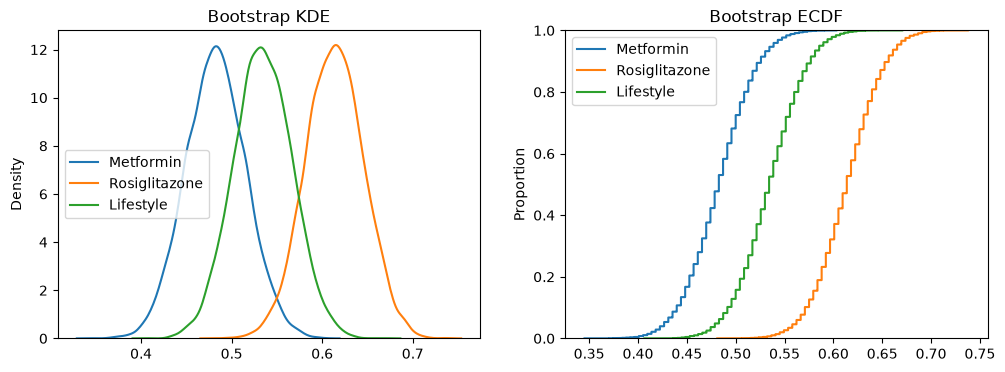

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', ax=ax[0])
sns.kdeplot(outcome_life, label='Lifestyle', ax=ax[0])

sns.ecdfplot(outcome_met, label='Metformin', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', ax=ax[1])
sns.ecdfplot(outcome_life, label='Lifestyle', ax=ax[1])

ax[0].set_title('Bootstrap KDE')
ax[1].set_title('Bootstrap ECDF')

ax[0].legend()
ax[1].legend()

plt.show()

Looking at the KDE distribution, we can see that it is bell shaped. The rosiglitazone shows the highest success rate while metformin shows the worst and that is still true for the ECDF plot. The KDE has the shapes overlapping.

Question 4

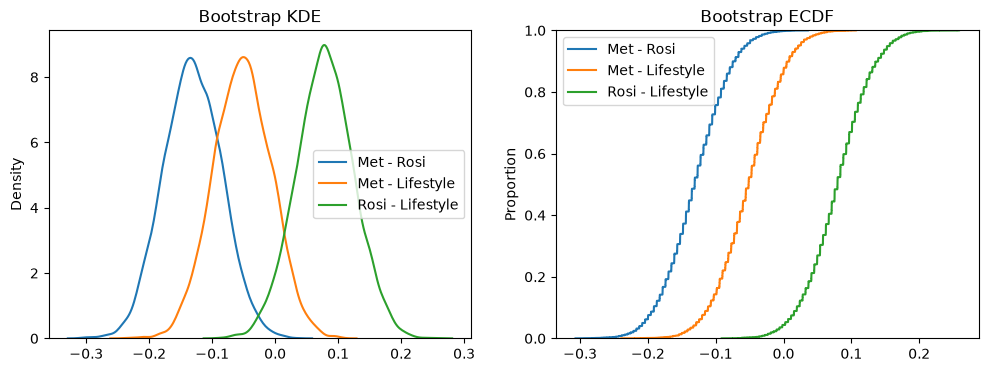

In [9]:
ate_met_rosi = np.array(outcome_met) - np.array(outcome_rosi)
ate_met_life = np.array(outcome_met) - np.array(outcome_life)
ate_rosi_life = np.array(outcome_rosi) - np.array(outcome_life)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for values, name in [(ate_met_rosi, 'Met - Rosi'),
                     (ate_met_life, 'Met - Lifestyle'),
                     (ate_rosi_life, 'Rosi - Lifestyle')]:

    sns.kdeplot(values, label=name, ax=ax[0])
    sns.ecdfplot(values, label=name, ax=ax[1])

ax[0].set_title('Bootstrap KDE')
ax[1].set_title('Bootstrap ECDF')

ax[0].legend()
ax[1].legend()

plt.show()

Question 5

In [10]:
for name, ate in [('Met - Rosi', ate_met_rosi),
                  ('Met - Lifestyle', ate_met_life),
                  ('Rosi - Lifestyle', ate_rosi_life)]:

    ci90 = np.quantile(ate, [.05, .95])
    ci95 = np.quantile(ate, [.025, .975])
    ci99 = np.quantile(ate, [.005, .995])

    print(name)
    print(f"90% CI: {ci90}")
    print(f"95% CI: {ci95}")
    print(f"99% CI: {ci99}")
    print()

Met - Rosi
90% CI: [-0.20822943 -0.05377756]
95% CI: [-0.21716368 -0.04068004]
99% CI: [-0.2471327  -0.01071093]

Met - Lifestyle
90% CI: [-0.12850169  0.02180961]
95% CI: [-0.14154141  0.0382101 ]
99% CI: [-0.16736737  0.06447097]

Rosi - Lifestyle
90% CI: [0.00251275 0.15652397]
95% CI: [-0.01041827  0.16950956]
99% CI: [-0.0360957   0.19518736]



It seems that we can reject the null hypothesis for all confidence intervals for the metformin vs rosiglitaszone because the intervals dont contain 0's. You can say the same for the 90% CI for rosiglitaszone vs lifestyle. I believe that rosiglitazone has the highest success rate.

## Report by Caleb Christian

We conducted this study to compare the effectiveness of 3 solutions to diabetes(rosiglitazone, metformin, and lifestyle changes). We performed this study to see if such solutions were successes or failures and compare the success rates between them to see which method is best for diabetes. We took 10,000 resamples and performed bootstrapping to confirm our results.

As shown in the table below, we can see that rosiglitazone had the highest success rate at approximately 61%, lifestyle adjustments came in second at 53% and metformin in third at 48%. Taking a look at the first pair of graphs, we can observe that the distribution for the KDE was bell shaped and overlapped with the rosiglitazone closer to the right. The ECDF graph shows as well that the rosiglitazone is closest to the right witht the highest success rates. These showings might suggest to us that rosiglitazone is the most effective.

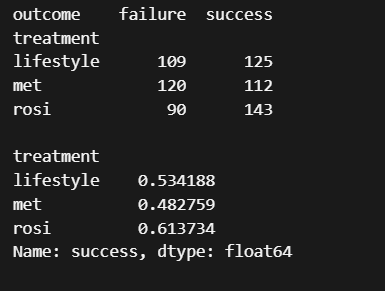

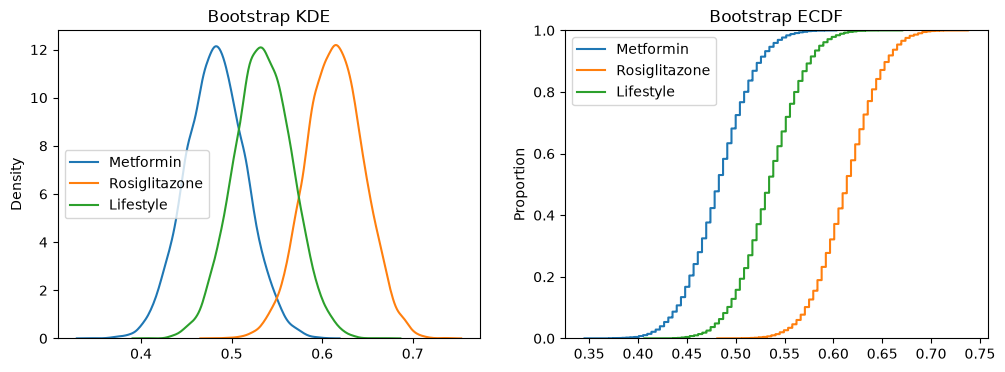

We then calculated the confidence intervals between comparisons of the different solutions. Looking at table 2, we can see the confidence intervals for comparing Metformin and Rosiglitazone are all below 0. This means that there is no 0 in the confidence intervals which makes it statistically significant. We reject the null hypothesis here. A special case is similar for comparing Rosiglitazone to Lifestyle changes. Also taking a glance at graph 2, the KDE shows that the shapes are bellshaped and the plots are overlapped. We can see the comparison of Rosiglitazone vs Lifestyle is closest to the right and has the highest numbers.

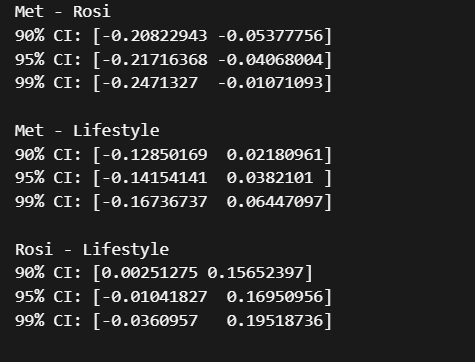

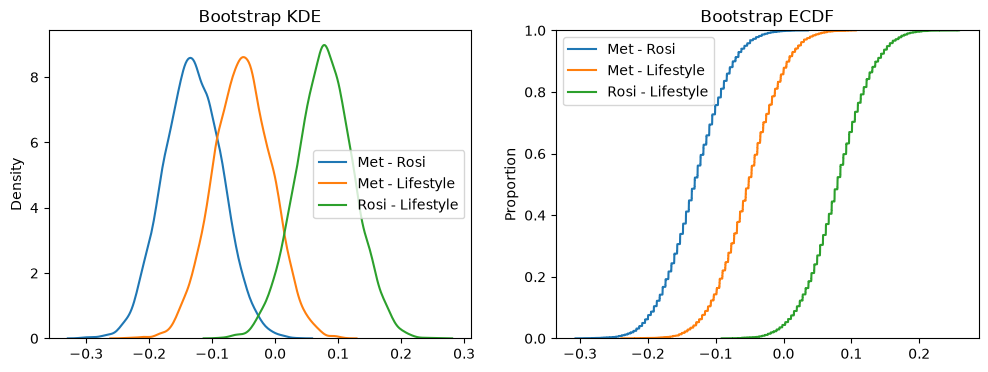

In conclusion, we estimate that using this dataset, Rosiglitazone has the most effect on diabetes compared to the other 2 methods. Due to its higher success rate and evidence of improvement compared to metformin and lifestyle changes, Rosiglitazone would be the method to suggest.